# Day 23 — Data Cleaning
**Project 1: Retail Sales & Customer Performance Analysis**  
Institute requirement: Missing values, duplicates, data types, invalid sales, category standardization, date validation, reusable `clean_data.py`, and Before → Process → After evidence.

**Dataset:** 30-row Day 22 retail sales CSV. Original is preserved. No Profit or Region columns exist.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from clean_data import clean_retail_data
folder = Path.cwd()
raw = pd.read_csv(folder / 'retail_sales.csv')
print('Original shape:',raw.shape)
display(raw.head())

Original shape: (30, 10)


,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating
0,ORD001,2026-10-02,Rahul,Mumbai,Clothing,T-Shirt,2,650,1300,5.0
1,ORD002,2026-10-03,Neha,Nagpur,Grocery,Rice,3,320,960,3.0
2,ORD003,2026-10-04,Vikram,Nashik,Home,Lamp,4,1100,4400,4.0
3,ORD004,2026-10-05,Priya,Pune,Electronics,Headphones,5,1500,7500,5.0
4,ORD005,2026-10-06,Arjun,Pune,Clothing,T-Shirt,1,650,650,4.0


## 1. Before: missing values and duplicates

In [2]:
print('Missing values before:')
display(raw.isna().sum().to_frame('Missing count'))
print('Exact duplicates:', raw.duplicated().sum())
print('Duplicate Order_ID:', raw['Order_ID'].duplicated().sum())

Missing values before:


,Missing count
Order_ID,0
Order_Date,0
Customer_Name,0
City,0
Category,0
Product,0
Quantity,0
Unit_Price,0
Sales,0
Customer_Rating,3


Exact duplicates: 0
Duplicate Order_ID: 0


## 2. Validate dates, sales and categories before cleaning

In [3]:
dates=pd.to_datetime(raw['Order_Date'],errors='coerce')
print('Invalid dates:',dates.isna().sum())
print('Future dates as of 2026-11-23:',(dates>pd.Timestamp('2026-11-23')).sum())
print('Negative sales:',(raw['Sales']<0).sum())
print('Quantity <= 0:',(raw['Quantity']<=0).sum())
print('Sales != Quantity × Unit_Price:',((raw['Sales']-raw['Quantity']*raw['Unit_Price']).abs()>0.01).sum())
print('Original category spellings:',sorted(raw['Category'].dropna().unique()))

Invalid dates: 0
Future dates as of 2026-11-23: 0
Negative sales: 0
Quantity <= 0: 0
Sales != Quantity × Unit_Price: 0
Original category spellings: ['Clothing', 'Electronics', 'Grocery', 'Home']


## 3. Cleaning strategy
- Remove only **exact duplicate rows**; audit duplicate order identifiers separately.
- Parse dates and numeric columns; reject invalid critical records for manual review rather than silently discarding them.
- Strip whitespace and standardize known category variants.
- Impute missing customer ratings using the observed **median**, preserving a boolean imputation flag. Ratings are subjective and median is robust to extreme values.
- Check sales against quantity × unit price. Negative sales may represent returns, so flag them for review rather than automatically changing values.

In [4]:
cleaned, audit=clean_retail_data(raw,as_of_date='2026-11-23')
print('Audit log:')
display(pd.DataFrame([{'Check':k,'Value':v} for k,v in audit.items()]))
display(cleaned.loc[cleaned['Customer_Rating_Was_Imputed'],['Order_ID','Customer_Rating','Customer_Rating_Was_Imputed']])

Audit log:


,Check,Value
0,rows_before,30.0
1,exact_duplicates,0.0
2,missing_ratings_before,3.0
3,category_values_standardized,0.0
4,invalid_dates,0.0
5,future_dates,0.0
6,duplicate_order_ids,0.0
7,negative_sales,0.0
8,nonpositive_quantities,0.0
9,negative_unit_prices,0.0


,Order_ID,Customer_Rating,Customer_Rating_Was_Imputed
6,ORD007,4.0,True
17,ORD018,4.0,True
28,ORD029,4.0,True


## 4. After: verification and comparison

In [5]:
comparison=pd.DataFrame({'Measure':['Rows','Missing ratings','Exact duplicate rows','Total sales','Distinct categories'],
'Before':[len(raw),int(raw.Customer_Rating.isna().sum()),int(raw.duplicated().sum()),float(raw.Sales.sum()),raw.Category.nunique()],
'After':[len(cleaned),int(cleaned.Customer_Rating.isna().sum()),int(cleaned.duplicated().sum()),float(cleaned.Sales.sum()),cleaned.Category.nunique()]})
display(comparison)
assert len(cleaned)==30
assert cleaned.Customer_Rating.isna().sum()==0
assert cleaned.Sales.sum()==raw.Sales.sum()
assert not cleaned.duplicated().any()
print('All checks passed.')

,Measure,Before,After
0,Rows,30.0,30.0
1,Missing ratings,3.0,0.0
2,Exact duplicate rows,0.0,0.0
3,Total sales,81870.0,81870.0
4,Distinct categories,4.0,4.0


All checks passed.


## 5. Visualization: missing values before and after

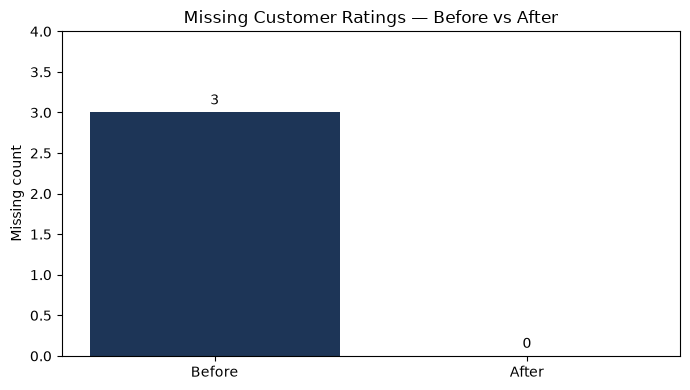

In [6]:
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(['Before','After'],[raw.Customer_Rating.isna().sum(),cleaned.Customer_Rating.isna().sum()],color=['#1D3557','#0F9D92'])
ax.set(title='Missing Customer Ratings — Before vs After',ylabel='Missing count',ylim=(0,4))
for i,v in enumerate([raw.Customer_Rating.isna().sum(),cleaned.Customer_Rating.isna().sum()]):ax.text(i,v+0.1,str(v),ha='center')
plt.tight_layout()
plt.savefig(folder/'missing_values_before_after.png',dpi=160)
plt.show()

## 6. Export final outputs

In [7]:
cleaned.to_csv(folder/'cleaned_retail_sales.csv',index=False)
pd.DataFrame([{'Check':k,'Value':v} for k,v in audit.items()]).to_csv(folder/'cleaning_audit.csv',index=False)
comparison.to_csv(folder/'before_after_comparison.csv',index=False)
print('Saved cleaned_retail_sales.csv, cleaning_audit.csv and before_after_comparison.csv')
print('Final dataset shape:',cleaned.shape)
display(cleaned.head())

Saved cleaned_retail_sales.csv, cleaning_audit.csv and before_after_comparison.csv
Final dataset shape: (30, 11)


,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating,Customer_Rating_Was_Imputed
0,ORD001,2026-10-02,Rahul,Mumbai,Clothing,T-Shirt,2,650,1300,5.0,False
1,ORD002,2026-10-03,Neha,Nagpur,Grocery,Rice,3,320,960,3.0,False
2,ORD003,2026-10-04,Vikram,Nashik,Home,Lamp,4,1100,4400,4.0,False
3,ORD004,2026-10-05,Priya,Pune,Electronics,Headphones,5,1500,7500,5.0,False
4,ORD005,2026-10-06,Arjun,Pune,Clothing,T-Shirt,1,650,650,4.0,False


## Conclusion
All 30 orders were retained; three missing ratings were filled with the observed median (4.0), with flags for transparency. No exact duplicates, invalid dates, future dates, negative sales, or arithmetic mismatches were found. The source has `City`, not `Region`, and no `Profit` field. These must not be invented. The cleaned dataset is ready for Day 24 transformation.